**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_025_초급_분류_건물에너지수요예측

### **건물 에너지 수요 예측 — <span style="color:darkgreen">피크 수요 여부</span> 예측 모델 개발**
---

- 도메인 : 건물 에너지 수요 예측
- 목  표 : 피크 시간대 전력 수요 발생 여부를 예측하는 인공지능모델 개발
- 에너지관리팀은 기상·운영 데이터로 시간대별 수요를 예측해 절감 방안을 찾으려 한다.
- 피크 요금 부담이 커져 든든파워의 고객 건물은 전력 수요를 미리 예측할 필요가 있다.
- 분석에는 약 800건 규모의 건물 데이터가 제공된다.
- 피크 수요 여부를 미리 알 수 있다면 든든파워의 운영 효율이 크게 개선될 것으로 보고 있다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 든든파워의 데이터로 피크 시간대 전력 수요 발생 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, unique, nunique, quantile, reset_index, drop, dropna, sum, isnull, get_dummies, info, DataFrame, columns, sort_values, shape) · seaborn(boxplot) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, MinMaxScaler, fit_transform, transform, KNeighborsClassifier, fit, DecisionTreeClassifier, feature_importances_, score) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Dropout, RMSprop, history)
- 난이도 : 초급 (설계 난이도 점수 2.45 / 5)
- 예상 소요 시간 : 약 113분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 건물 에너지 수요 예측 (에너지)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- Uid                   : 고유 식별번호
- Outdoor_Temp          : 외기 온도(℃)
- Humidity              : 상대 습도(%)
- Floor_Area            : 연면적(천㎡)
- Occupancy             : 재실 인원 비율(%)
- Solar_Rad             : 일사량(MJ/㎡)
- It_Load_Kw            : 전산 설비 부하(kW)
- Chiller_Cop           : 냉동기 효율(COP)
- Lag_Load_Kw           : 전일 동시각 전력(kW)
- Contract              : 계약 종별
- Region                : 지역
- Day_Type              : 요일 구분
- Peak_Flag             : 피크 수요 여부 (0: Normal, 1: Peak)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- import 할 모듈 : `pandas`
- as 뒤에 쓸 이름(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pd'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 2글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as p_

정답01 = 'p_'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 다음 지침에 따라 파일을 읽어 data 에 저장하고 처음 5개 행을 확인하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 읽은 결과를 담을 변수 : data / 대상 파일 : data.csv
    - 경로 없이 파일 이름만으로 읽을 수 있습니다
- **[정답02]** 읽어 온 데이터의 **열(column)의 개수** 를 작성하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [5]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

print(data.shape[1])


13


In [6]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 13

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 data 로 열(column)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(data.shape[__])
```

</details>

### **3. 요일 구분(Day_Type) 컬럼에 몇 종류의 값이 있는지 확인하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(unique, nunique) | 난이도: 기초 | 예상 시간: 3분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- data 의 Day_Type 컬럼의 고유한 값 목록을 `unique()` 로 구해 `levels` 에, 고유한 값의 **개수**를 `nunique()` 로 구해 `n_levels` 에 보관하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [7]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

levels = data['Day_Type'].unique()
n_levels = data['Day_Type'].nunique()

In [8]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'nunique'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

값 목록을 돌려주는 메서드와 개수를 세는 메서드를 각각 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `unique`, `nunique`. 정답은 7글자이고 첫 글자는 `n` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
levels = data['Day_Type'].unique()
n_levels = data['Day_Type'].nuni___()

정답03 = 'nuni___'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 요일 구분(Day_Type) 별 재실 인원 비율(%)(Occupancy)의 분포를 확인하려 합니다. 아래 안내대로 boxplot으로 시각화하세요.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(boxplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- seaborn 의 boxplot 으로 재실 인원 비율(%)(Occupancy) 컬럼의 분포를 그래프로 그리세요
- X축에는 요일 구분(Day_Type)를, Y축에는 재실 인원 비율(%)(Occupancy)를 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44277 (\N{HANGUL SYLLABLE GONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 55092 (\N{HANGUL SYLLABLE HYU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

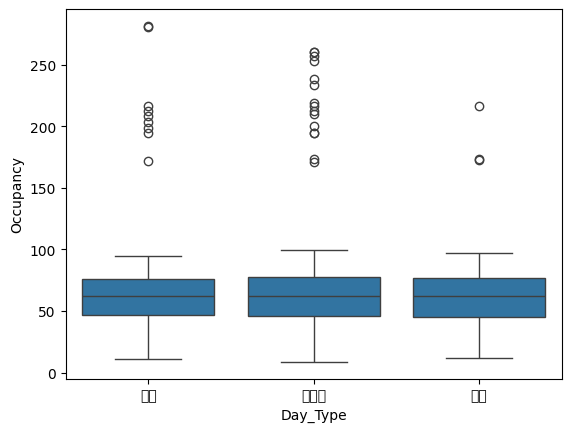

In [9]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.boxplot(data=data, x='Day_Type', y='Occupancy')
plt.show()

In [10]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'boxplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

그룹별 분포와 이상치를 상자 그림으로 보여주는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.boxplot`. 정답은 7글자이고 첫 글자는 `b` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxp___(data=data, x='Day_Type', y='Occupancy')
plt.show()

정답04 = 'boxp___'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 재실 인원 비율(%)(Occupancy) 컬럼의 이상치를 IQR 기준으로 제거할 계획입니다. 제시된 가이드에 맞춰 처리하십시오.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- 사분위수(Q1, Q3)와 IQR 을 구하세요
- lower_fence = Q1 - 1.5 x IQR, upper_fence = Q3 + 1.5 x IQR 로 정의하세요
- Occupancy 이(가) 두 fence 밖에 있는 행을 삭제하세요
- 식별자 컬럼 Uid 도 삭제하고 인덱스를 0부터 다시 매겨 data_temp 에 저장하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [11]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

q1 = data['Occupancy'].quantile(0.25)
q3 = data['Occupancy'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (data['Occupancy'] > upper_fence) | (data['Occupancy'] < lower_fence)
data_temp = data[~is_out].drop(columns=['Uid']).reset_index(drop=True)

In [12]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'quantile'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`. 정답은 8글자이고 첫 글자는 `q` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = data['Occupancy'].quan____(0.25)
q3 = data['Occupancy'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (data['Occupancy'] > upper_fence) | (data['Occupancy'] < lower_fence)
data_temp = data[~is_out].drop(columns=['Uid']).reset_index(drop=True)

정답05 = 'quan____'   # 빈칸에 넣은 단어
```

</details>

### **6. 제시된 가이드에 맞춰 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 코드의 오류를 정정하세요
    - 대상 데이터프레임 : data_temp
    - 결측치 개수를 확인한 뒤, 결측치가 있는 행을 모두 삭제해 data_na 에 보관하세요
    - 처리 후 결측치가 사라졌는지 확인하세요
- **[정답06]** 처리 전 data_temp 의 결측치는 총 몇 개로 나타나나요?
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [14]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

print('결측치 처리 전\n', data_temp.isnull().sum())
data_na = data_temp.dropna()
print('결측치 처리 후\n', data_na.isnull().sum())

결측치 처리 전
 Outdoor_Temp     0
Humidity         0
Floor_Area      59
Occupancy        0
Solar_Rad        0
It_Load_Kw       0
Chiller_Cop      0
Lag_Load_Kw      0
Contract        16
Region           0
Day_Type         0
Peak_Flag        0
dtype: int64
결측치 처리 후
 Outdoor_Temp    0
Humidity        0
Floor_Area      0
Occupancy       0
Solar_Rad       0
It_Load_Kw      0
Chiller_Cop     0
Lag_Load_Kw     0
Contract        0
Region          0
Day_Type        0
Peak_Flag       0
dtype: int64


In [15]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 'dropna'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치 확인 -> 삭제 -> 재확인 순서로 코드를 읽어 보세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
print('결측치 처리 전\n', data_temp.isnull().sum())
data_na = data_temp.dropna()
print('결측치 처리 후\n', data_na.isnull().sum())

# [정답06] 실행한 결과를 입력하세요
data_temp.isnull().sum().sum()
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 변환하는 코드를 수정하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `data_na`
- 아래 안내대로 인코딩하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - 대상 데이터프레임 : data_na
    - 문자열(범주형) 컬럼 Contract, Region, Day_Type 을(를) get_dummies 로 인코딩하세요 (타깃 Peak_Flag 은 제외, drop_first=False)
    - 인코딩된 데이터프레임은 data_preset 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 data_preset 의 **전체 컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [17]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

data_preset = pd.get_dummies(data=data_na, columns=['Contract', 'Region', 'Day_Type'], drop_first=False)
data_preset.info()
print(data_preset)

<class 'pandas.core.frame.DataFrame'>
Index: 698 entries, 0 to 771
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Outdoor_Temp  698 non-null    float64
 1   Humidity      698 non-null    float64
 2   Floor_Area    698 non-null    float64
 3   Occupancy     698 non-null    float64
 4   Solar_Rad     698 non-null    float64
 5   It_Load_Kw    698 non-null    float64
 6   Chiller_Cop   698 non-null    float64
 7   Lag_Load_Kw   698 non-null    float64
 8   Peak_Flag     698 non-null    int64  
 9   Contract_교육용  698 non-null    bool   
 10  Contract_산업용  698 non-null    bool   
 11  Contract_일반용  698 non-null    bool   
 12  Region_경기     698 non-null    bool   
 13  Region_서울     698 non-null    bool   
 14  Region_영남     698 non-null    bool   
 15  Region_충청     698 non-null    bool   
 16  Region_호남     698 non-null    bool   
 17  Day_Type_공휴일  698 non-null    bool   
 18  Day_Type_주말   698 non-null    bool 

In [18]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 20

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data_preset = pd.get_dummies(data=data_na, columns=['Contract', 'Region', 'Day_Type'], drop_first=False)
data_preset.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_preset.shape[__]
```

</details>

### **8. 모델 성능을 확인할 검증 데이터를 따로 떼어 두려고 합니다. 제시된 가이드에 맞춰 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 대상 데이터프레임 : data_preset
- 피크 수요 여부(Peak_Flag) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 훈련 75%, 검증 25% 비율로 나누세요 (test_size=0.25)
- scikit-learn 의 train_test_split 함수를 활용하세요 / 클래스 비율을 유지하는 층화 추출(stratify=y)을 적용하세요
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- 난수 시드(random_state)는 100 로 설정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [19]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = data_preset.drop('Peak_Flag', axis=1)
y = data_preset['Peak_Flag']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=100, stratify=y)

In [20]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'test_size'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 9글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = data_preset.drop('Peak_Flag', axis=1)
y = data_preset['Peak_Flag']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_____=0.25, random_state=100, stratify=y)

정답08 = 'test_____'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 가이드에 따라 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 sc 변수에 할당하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[정답09]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수점 둘째 자리까지 입력하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [23]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

import numpy as np

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)
print(X_valid.min())

-0.05059523809523825


In [24]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = -0.05

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 피크 수요 여부(Peak_Flag)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsClassifier, fit, DecisionTreeClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=15, weights='distance'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=5, min_samples_leaf=10
    - 난수 시드(random_state) : 7
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **잎(leaf) 노드 수** `dt.get_n_leaves()` 는 몇 개입니까?
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [27]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15, weights='distance')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=7)
dt.fit(X_train, y_train)

dt.get_n_leaves()

np.int64(20)

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [28]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 20

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 결정나무 모델의 get_n_leaves() 메서드를 호출하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsClassifier`, `fit`, `DecisionTreeClassifier`, `get_n_leaves`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15, weights='distance')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=7)
dt.fit(X_train, y_train)

# [정답10] 실행한 결과를 입력하세요
dt.get_n_leaves()
```

</details>

### **11. DecisionTree 모델의 변수중요도 상위 5개 변수가 전체 설명력의 얼마를 차지하는지 확인하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, reset_index, head, columns) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `dt`
- 학습된 DecisionTree 모델 `dt` 의 변수중요도를 변수명과 매핑한 DataFrame `fi` 로 만들고 내림차순 정렬하세요
    - 상위 5개 행을 `top_n` 에 저장하세요
- **[정답11]** 상위 5개 변수 중요도의 **합계**를 소수점 아래 둘째 자리까지 기입하세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [29]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(5)

round(top_n['importance'].sum(), 2)


np.float64(1.0)

In [ ]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 1.00

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 DataFrame 을 만들어 정렬한 뒤 위에서 N개를 선택합니다. top_n 의 importance 컬럼을 합하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `feature_importances_`, `sort_values`, `head`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(5)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(top_n['____'].sum(), __)
```

</details>

### **12. DecisionTree 모델의 기본 평가 점수를 `score` 메서드로 간단히 확인하고자 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`
- 학습된 DecisionTree 모델 `dt` 의 `score(X_valid, y_valid)` 값을 `score_dt` 에 보관하세요 (분류는 정확도, 회귀는 결정계수 R2 를 돌려줍니다)
- **[정답12]** `score_dt` 를 소수점 셋째 자리까지 기입하세요
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [30]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
score_dt = dt.score(X_valid, y_valid)
round(score_dt, 3)


0.777

In [31]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 0.777

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

학습된 모델 객체의 score 메서드에 검증 데이터를 넣습니다. score 값을 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

사용할 도구: `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
score_dt = dt.score(X_valid, y_valid)

# [정답12] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(score_dt, __)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [32]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(100)

### **13. 피크 수요 여부(Peak_Flag)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- TensorFlow(Keras) 로 구현하세요
- Dense 은닉층 2개를 노드 수 [32, 16] 순서로 쌓고, 활성화 함수는 'elu' 를 쓰세요
- 조기 종료 : EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True) 를 만들어 estop 에 보관하세요
- 첫 번째 은닉층 뒤에 Dropout(0.5) 층을 두세요
- 마지막 Dense 층 : 노드 1개 · 활성화 함수 'sigmoid'
- optimizer 는 문자열이 아니라 RMSprop(learning_rate=0.001) 객체로 지정하고, loss 는 binary_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
- batch_size 는 32, epochs 는 30 로 학습하고 학습정보는 history 변수에 저장하세요 (검증 데이터: X_valid, 검증 레이블)
- 안내하지 않은 파라미터는 지정하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [33]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(32, activation='elu', input_dim=X_train.shape[1]),
    Dropout(0.5),
    Dense(16, activation='elu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer=RMSprop(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=32,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.5239 - loss: 0.7162 - val_accuracy: 0.5029 - val_loss: 0.6905
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5526 - loss: 0.6907 - val_accuracy: 0.5600 - val_loss: 0.6824
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6061 - loss: 0.6728 - val_accuracy: 0.5886 - val_loss: 0.6770
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6138 - loss: 0.6594 - val_accuracy: 0.6171 - val_loss: 0.6723
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5813 - loss: 0.6603 - val_accuracy: 0.6400 - val_loss: 0.6673
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6214 - loss: 0.6502 - val_accuracy: 0.6457 - val_loss: 0.6598
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6291 - loss: 0.6489 - val_accuracy: 0.6571 - val_loss: 0.6535
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6348 - loss: 0.6414 - val_accuracy: 0.6514 - v

In [34]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = RMSprop

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 모델을 학습시킬 때 가중치를 갱신하는 최적화 알고리즘의 이름입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 7글자이고 첫 글자는 `R` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(32, activation='elu', input_dim=X_train.shape[1]),
    Dropout(0.5),
    Dense(16, activation='elu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer=RMSp___(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=32,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

정답13 = 'RMSp___'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Accuracy와(과) 검증 Accuracy의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 그래프 1개 안에 학습 Accuracy·검증 Accuracy 두 선을 모두 그리세요
- 그래프의 타이틀은 'Model Accuracy' 로, X축 이름은 'Epochs', Y축 이름은 'Accuracy' 로 표시하세요
- 범례를 'train', 'val' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

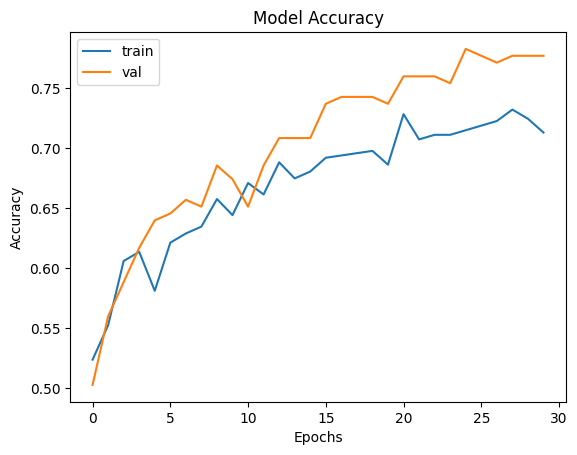

In [35]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'])
plt.show()

In [37]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'history'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. fit 이 돌려준 학습 기록 객체의 변수명입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 7글자이고 첫 글자는 `h` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(hist___.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'])
plt.show()

정답14 = 'hist___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.